# E3: Adversarially pretrained ResNet-50 fine-tuned on MSLD v2.0

E3 tests a different route to robustness. Instead of making a clean-trained DenseNet robust from scratch (E1, E2), it starts from a ResNet-50 whose ImageNet features were already trained against L-infinity attacks (Salman et al., 2020, "Do adversarially robust ImageNet models transfer better?"), replaces the classifier with global average pooling and one linear layer (2048 x 6 + 6 = 12,294 parameters), and fine-tunes it on our five folds. Data, folds, leakage checks and augmentation are the same as in B0, B2 and E1.

The idea: with only about 530 training images per fold, a model that must learn robust features from scratch has little to learn them from. A robust pretrained backbone already carries features that do not flip under tiny perturbations, and Salman et al. found that such models transfer to new tasks as well as or better than standard ones.

Two settings define the experiment (both in section 2):

1. `PRETRAIN`: `"robust_eps0.5"`, `"robust_eps1.0"` (default), `"robust_eps2.0"`, `"robust_eps4.0"` or `"standard"`. The robust options are the L-infinity ResNet-50 checkpoints of Salman et al. trained at that budget in units of 1/255 (ImageNet clean accuracy 73.7%, 72.1%, 69.1%, 63.9%); `"standard"` is the normal torchvision ImageNet ResNet-50, kept as a control so that the effect of the robust initialisation can be separated from the effect of the architecture.
2. `LOSS_MODE`: `"clean"` (fine-tune on clean images only, the cheapest test of what robust pretraining gives for free), `"pgd_at"` (adversarial fine-tuning, the default and the full E3 recipe) or `"trades"`.

A good set of runs for the report: (a) robust_eps1.0 + clean, to see what the pretrained features alone give; (b) robust_eps1.0 + pgd_at, the main E3 result; (c) standard + pgd_at, to see how much the robust initialisation adds on top of adversarial training.

Choices I made:

- **Where the weights come from.** The notebook looks for the checkpoint file (for example `resnet50_linf_eps1.0.ckpt`) under `/kaggle/input` first and otherwise downloads it from the Hugging Face repository `madrylab/robust-imagenet-models` (needs Internet). If the download is blocked, download the file on your computer and add it to the notebook as a Kaggle dataset. The checkpoint format could not be checked while writing this notebook, so the loader prints what it finds and stops with a clear message if the keys do not match.
- **Pixel space.** As in E1, normalisation sits inside the model and the attack works in raw [0,1] pixel space. The Salman et al. models were trained with the standard ImageNet mean and standard deviation, which is what is used here.
- **Learning rates.** The pretrained backbone gets a small rate (`LR_BACKBONE = 1e-5`) so the robust features are not erased, and the new head gets a larger one (`LR_HEAD = 1e-4`). Both are different from B0, B2 and E1, so state them in the report.
- **BatchNorm.** The default PyTorch momentum of 0.1 is kept, since ResNet-50 here is not a Keras port. Attacks are built in eval mode, as in E1.
- **Checkpoint choice and evaluation** are as in E1: the best-validation weights are picked by robust validation accuracy (PGD-`VAL_STEPS` at `VAL_EPS255`), and each fold is scored on the test set with APGD-DLR (20 steps, 1 restart, full precision) for the final and the best-validation weights.
- **Cost.** ResNet-50 is cheaper per step than DenseNet121, and `"clean"` mode needs no attack. The defaults (3 attack steps, 40 epochs, REPEAT 4) are the same as E1, so expect a similar or shorter run.

To run on Kaggle: add the MSLD v2.0 dataset as an input, turn on a GPU and Internet. First set `QUICK = True` and run everything once, then set it back to `False`. A resume checkpoint is saved every 10 epochs; to continue after a session ended, add the earlier output as an input and set `RESTORE_FROM`. Curves and test metrics go to Weights & Biases if a `WANDB_API_KEY` secret exists. Install `torchattacks` once with `!pip install -q --no-deps torchattacks`.


## 1. Imports

In [1]:
# All of these come preinstalled on Colab and Kaggle
import os, time, random, json, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
# torchattacks is used only for the final APGD-DLR evaluation. On Kaggle install it without dependencies:
# run `!pip install -q --no-deps torchattacks` once, then restart the session if pip changed any package.
try:
    import torchattacks
    print("torchattacks:", torchattacks.__version__)
except Exception as e:
    torchattacks = None
    print("torchattacks not installed; the final APGD evaluation will be skipped:", e)


Device: cuda
GPU: Tesla T4
PyTorch: 2.11.0+cu128
torchattacks not installed; the final APGD evaluation will be skipped: No module named 'torchattacks'


## 2. Settings

In [2]:
# Settings kept from B0/B2/E1
IMG = 224
BATCH = 16
NUM_CLASSES = 6
USE_AMP = True
CKPT_EVERY = 10
SEED = 42
NUM_WORKERS = 2
FOLDS = [1, 2, 3, 4, 5]

# What E3 changes
PRETRAIN = "robust_eps1.0"   # "robust_eps0.5" | "robust_eps1.0" | "robust_eps2.0" | "robust_eps4.0" | "standard"
LOSS_MODE = "pgd_at"         # "clean" | "pgd_at" | "trades"
TRAIN_EPS255 = 0.5           # training budget for pgd_at / trades, in units of 1/255 (ignored for "clean")
TRAIN_STEPS = 3              # PGD steps while training; alpha = 2.5 * eps / steps
LAMBDA_CLEAN = 0.0           # pgd_at only: weight of an added clean-image loss
BETA = 6.0                   # trades only
VAL_EPS255 = 0.5             # budget of the robust validation accuracy that picks the best epoch (all modes)
VAL_STEPS = 10
LOSS_SCALE = 256.0           # attack loss scale under mixed precision; harmless because PGD uses only the gradient sign
LR_BACKBONE = 1e-5           # small, so the pretrained features are kept
LR_HEAD = 1e-4
EPOCHS = 40
REPEAT = 4

# Final evaluation: APGD-DLR budgets in units of 1/255
EVAL_EPS255 = [0.05, 0.1, 0.25, 0.5, 1.0, 2.0]
EVAL_STEPS = 20

assert LOSS_MODE in ("clean", "pgd_at", "trades")
assert PRETRAIN in ("standard", "robust_eps0.5", "robust_eps1.0", "robust_eps2.0", "robust_eps4.0")
RUN_NAME = f"e3_{PRETRAIN}_{LOSS_MODE}" + ("" if LOSS_MODE == "clean" else f"_eps{TRAIN_EPS255}")

QUICK = False
if QUICK:
    EPOCHS, REPEAT, FOLDS = 2, 1, [1]
    RUN_NAME += "_quick"

OUT = Path(f"/kaggle/working/{RUN_NAME}")
OUT.mkdir(parents=True, exist_ok=True)
SAVE_WEIGHTS = True   # about 95 MB per model

USE_WANDB = True
WANDB_PROJECT = "mpox-e3-robust-resnet50"
RESTORE_FROM = None

# B0 numbers for the comparison plot (APGD-DLR, mean accuracy % over 5 folds, eps = 0, 0.05, 0.1, 0.25, 0.5 in 1/255)
B0_EPS = [0, 0.05, 0.1, 0.25, 0.5]
B0_ACC = {"B0 final": [79.14, 62.90, 47.09, 8.04, 0.0], "B0 best-val": [81.91, 61.38, 38.90, 4.35, 0.0]}


## 2b. Weights & Biases and restoring an earlier run

W&B logs the training curves and the test metrics of each fold; the model files stay in the output folder. Each fold is one W&B run with a fixed id, so a fold that is resumed after an interruption continues the same run. If the W&B login fails, logging is switched off and training carries on.

If `RESTORE_FROM` is set, finished folds (`fold{k}.json`) and the resume files of unfinished folds are copied from that folder into the output folder, so the next cell that trains skips what is done and resumes the rest.

In [3]:
import shutil

if USE_WANDB:
    try:
        import wandb
        from kaggle_secrets import UserSecretsClient
        wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"))
    except Exception as e:
        print("W&B off:", e)
        USE_WANDB = False

if RESTORE_FROM:
    found = {}
    for dp, _, fs in os.walk(RESTORE_FROM, followlinks=True):
        for name in fs:
            found.setdefault(name, Path(dp) / name)
    assert found, f"No files found under {RESTORE_FROM}"
    for k in range(1, 6):
        done = f"fold{k}.json"
        need = [done] if done in found else [f"{RUN_NAME}_fold{k}_last.pt", f"{RUN_NAME}_fold{k}_bestval.pt"]
        if not all(n in found for n in need):
            continue
        for name in need:
            if not (OUT / name).exists():
                shutil.copy2(found[name], OUT / name)
                print("restored", name)
print("OUT:", OUT, "| W&B:", USE_WANDB)


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: aolawal (aolawal-carnegie-mellon-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


OUT: /kaggle/working/e3_robust_eps1.0_pgd_at_eps0.5 | W&B: True


## 3. Point to the dataset

The notebook looks for the `FOLDS` folder of the original images under `/kaggle/input`. It uses the original images, not the augmented ones, because it augments on the fly.

In [4]:

def find_folds_root():
    for dirpath, dirnames, _ in os.walk("/kaggle/input", followlinks=True):
        if os.path.basename(dirpath) == "FOLDS" and "fold1" in dirnames:   # FOLDS_AUG (augmented) does not match
            return Path(dirpath)
    return None

DATA_ROOT = find_folds_root()
assert DATA_ROOT is not None, "Could not find the FOLDS folder. Add the MSLD v2.0 dataset to the notebook (Add Input)."
print("Using:", DATA_ROOT)


Using: /kaggle/input/datasets/joydippaul/mpox-skin-lesion-dataset-version-20-msld-v20/Original Images/Original Images/FOLDS


## 4. Read the folds

Image names follow the pattern `MKP_17_01`: disease code, patient number, image number. The class comes from the folder, and the patient comes from the file name. Each image also has a byte-identical copy named like `MKP_17_01_1`; I keep only the three-part names, otherwise the training set would double in size and every validation and test image would be counted twice.

For every fold I check that no image and no patient appears in two splits, and that the disease code in each file name agrees with its class folder.

In [5]:
CLASSES = ["Chickenpox", "Cowpox", "HFMD", "Healthy", "Measles", "Monkeypox"]   # folder names, alphabetical like Keras
CLS_ID = {c: i for i, c in enumerate(CLASSES)}
CODES = {"CHP": "Chickenpox", "CWP": "Cowpox", "HFMD": "HFMD", "HEALTHY": "Healthy", "MSL": "Measles", "MKP": "Monkeypox"}
EXTS = {".jpg", ".jpeg", ".png", ".bmp"}
SPLITS = {"train": "Train", "val": "Valid", "test": "Test"}

def is_original(stem):
    # "MKP_17_01" is an original; "MKP_17_01_1" is a byte-identical copy that we skip
    return len(stem.split("_")) == 3

def patient_of(stem):
    code, pid = stem.split("_")[:2]
    return f"{code.upper()}_{pid}"

def read_fold(k):
    data = {}
    for key, folder in SPLITS.items():
        items = []
        for c in CLASSES:
            for p in sorted((DATA_ROOT / f"fold{k}" / folder / c).iterdir()):
                if p.suffix.lower() in EXTS and is_original(p.stem):
                    assert CODES[p.stem.split("_")[0].upper()] == c, f"{p} sits in the wrong class folder"
                    items.append((p, CLS_ID[c]))
        data[key] = items
    return data

def check_fold(k, data):
    names = {key: {p.stem.lower() for p, _ in items} for key, items in data.items()}
    pats = {key: {patient_of(p.stem) for p, _ in items} for key, items in data.items()}
    for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
        assert not names[a] & names[b], f"Fold {k}: images shared between {a} and {b}"
        assert not pats[a] & pats[b], f"Fold {k}: patients shared between {a} and {b}"
    assert sum(len(v) for v in data.values()) == 755, f"Fold {k}: expected 755 original images"

fold_data, rows = {}, []
for k in FOLDS:
    fold_data[k] = read_fold(k)
    check_fold(k, fold_data[k])
    for key, items in fold_data[k].items():
        counts = np.bincount([y for _, y in items], minlength=NUM_CLASSES)
        rows.append({"fold": k, "split": key, "total": len(items), **dict(zip(CLASSES, counts))})

print("All folds passed the leakage and label checks.")
pd.DataFrame(rows)

All folds passed the leakage and label checks.


,fold,split,total,Chickenpox,Cowpox,HFMD,Healthy,Measles,Monkeypox
0,1,train,537,50,49,116,83,37,202
1,1,val,144,16,10,29,22,12,55
2,1,test,74,9,7,16,9,6,27
3,2,train,509,51,47,109,80,40,182
4,2,val,164,13,15,32,23,10,71
5,2,test,82,11,4,20,11,5,31
6,3,train,538,51,47,114,75,36,215
7,3,val,153,18,15,31,28,14,47
8,3,test,64,6,4,16,11,5,22
9,4,train,524,52,44,115,83,36,194


## 5. Data loading and augmentation

The training transforms follow the list in Section 4.3 of the paper: rotation, translation, reflection, shear, hue, saturation, contrast and brightness jitter, noise and scaling. As in Section 5.1, only the training images are augmented. Validation and test images are only resized. In E1 the ImageNet normalisation is done inside the model, so that attacks and epsilon live in raw [0,1] pixel space.

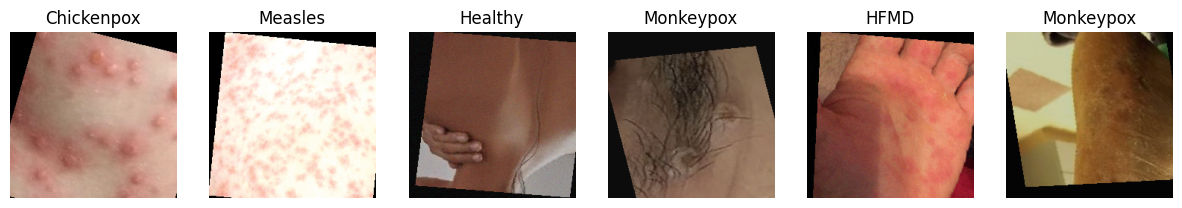

In [6]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

class AddNoise:
    # Small Gaussian noise, applied to half of the images
    def __init__(self, std=0.02, p=0.5):
        self.std, self.p = std, p
    def __call__(self, x):
        if random.random() < self.p:
            x = (x + torch.randn_like(x) * self.std).clamp(0, 1)
        return x

train_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomAffine(degrees=20, translate=(0.1, 0.1), scale=(0.9, 1.1), shear=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
    transforms.ToTensor(),
    AddNoise(),
])  # no Normalize here: the model normalises, so the attack works in raw [0,1] pixel space

test_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.ToTensor(),
])

class SkinData(Dataset):
    def __init__(self, items, tf, repeat=1):
        self.items = items * repeat   # repeat the list so one epoch sees each image `repeat` times
        self.tf = tf
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        path, y = self.items[i]
        img = Image.open(path).convert("RGB")
        return self.tf(img), y

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def seed_worker(_):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def make_loaders(k):
    data = fold_data[k]
    g = torch.Generator().manual_seed(SEED + k)
    # shuffle=True draws mini-batches without replacement, as in the paper
    train_dl = DataLoader(SkinData(data["train"], train_tf, REPEAT), batch_size=BATCH, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True, worker_init_fn=seed_worker, generator=g)
    val_dl = DataLoader(SkinData(data["val"], test_tf), batch_size=32, num_workers=NUM_WORKERS, pin_memory=True)
    test_dl = DataLoader(SkinData(data["test"], test_tf), batch_size=32, num_workers=NUM_WORKERS, pin_memory=True)
    return train_dl, val_dl, test_dl

# Look at a few augmented training images as a sanity check
x, y = next(iter(make_loaders(FOLDS[0])[0]))
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax, img, lab in zip(axes, x[:6], y[:6]):
    img = img.permute(1, 2, 0).numpy()
    ax.imshow(img.clip(0, 1)); ax.set_title(CLASSES[int(lab)]); ax.axis("off")
plt.show()

## 6. The model

ResNet-50 up to its last stage gives a 2048x7x7 feature map. Global average pooling reduces it to 2048 values and one linear layer maps them to the 6 classes (12,294 parameters; 23,520,326 in total). The backbone starts from the weights chosen with `PRETRAIN`. The ImageNet mean and standard deviation are applied inside the model, so inputs are raw [0,1] images.

The robust checkpoints come from the robustness library, where the model is wrapped, so their keys start with `module.model.`; the loader strips that prefix and ignores the wrapper's attacker and normaliser copies. It prints how many keys it matched and stops if anything beyond the 1000-class classifier is missing.

In [7]:
CKPT_URL = "https://huggingface.co/madrylab/robust-imagenet-models/resolve/main/resnet50_linf_eps{}.ckpt"

def find_or_download(eps):
    name = f"resnet50_linf_eps{eps}.ckpt"
    for dp, _, fs in os.walk("/kaggle/input", followlinks=True):
        if name in fs:
            return Path(dp) / name
    dst = Path("/kaggle/working") / name
    if not dst.exists():
        print("downloading", name)
        urllib.request.urlretrieve(CKPT_URL.format(eps), dst)
    return dst

def extract_resnet_state(sd):
    """Return the plain torchvision ResNet-50 state dict hidden inside a robustness-library checkpoint."""
    for pref in ("module.model.", "model.", "module."):
        sub = {k[len(pref):]: v for k, v in sd.items() if k.startswith(pref)}
        if "conv1.weight" in sub:
            return sub
    if "conv1.weight" in sd:
        return dict(sd)
    raise KeyError("No ResNet-50 weights found. First keys: " + ", ".join(list(sd.keys())[:8]))

def load_pretrained_resnet():
    net = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1) if PRETRAIN == "standard" else models.resnet50()
    if PRETRAIN != "standard":
        path = find_or_download(PRETRAIN.replace("robust_eps", ""))
        ck = torch.load(path, map_location="cpu", weights_only=False)
        sd = ck.get("model", ck.get("state_dict", ck)) if isinstance(ck, dict) else ck
        sub = {k: v for k, v in extract_resnet_state(sd).items() if not k.startswith("fc.")}
        missing, unexpected = net.load_state_dict(sub, strict=False)
        assert all(m.startswith("fc.") for m in missing) and not unexpected, f"checkpoint mismatch: missing {missing[:5]}, unexpected {unexpected[:5]}"
        print(f"Loaded {len(sub)} tensors from {path.name} (only the classifier was left out)")
    return net

class E3Net(nn.Module):
    def __init__(self, n_cls=NUM_CLASSES):
        super().__init__()
        r = load_pretrained_resnet()
        self.backbone = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool, r.layer1, r.layer2, r.layer3, r.layer4)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(2048, n_cls))
        self.register_buffer("mean", torch.tensor(MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(STD).view(1, 3, 1, 1))
        nn.init.xavier_uniform_(self.head[-1].weight)
        nn.init.zeros_(self.head[-1].bias)

    def forward(self, x):                      # x in [0, 1]
        return self.head(self.backbone((x - self.mean) / self.std))

tmp = E3Net()
n_back = sum(p.numel() for p in tmp.backbone.parameters())
n_head = sum(p.numel() for p in tmp.head.parameters())
print(f"Backbone: {n_back:,}   Head: {n_head:,}   Total: {n_back + n_head:,}")
assert n_head == 12_294 and n_back + n_head == 23_520_326
del tmp

downloading resnet50_linf_eps1.0.ckpt
Loaded 318 tensors from resnet50_linf_eps1.0.ckpt (only the classifier was left out)
Backbone: 23,508,032   Head: 12,294   Total: 23,520,326


## 7. Attacks, training and evaluation functions

- `pgd` builds L-infinity attack images in raw pixel space with a random start. With `mode="ce"` it maximises cross-entropy (PGD-AT); with `mode="kl"` it maximises the KL divergence from the clean output (TRADES).
- `run_epoch` trains one epoch on attacked images (or on clean images when `LOSS_MODE = "clean"`) (the attack is built in eval mode, the update in train mode) and returns the loss and the accuracy on the attacked training images.
- `evaluate` returns clean validation accuracy and loss, plus robust accuracy under PGD-`VAL_STEPS` at `VAL_EPS255`, which is what picks the best epoch.
- `apgd_eval` runs the final APGD-DLR evaluation in full precision at the budgets in `EVAL_EPS255` and returns accuracy, mpox recall and the mpox miss rate (the share of mpox images detected on clean input that the attack hides).

`train_fold` trains one fold, keeps the final weights and the best-validation weights (by robust validation accuracy), then scores both on the test set, clean and under APGD-DLR. Finished folds are saved to `OUT/fold{k}.json` and skipped on a rerun.

In [8]:
EPS = TRAIN_EPS255 / 255.0
VAL_EPS = VAL_EPS255 / 255.0
ALPHA = 2.5 * EPS / TRAIN_STEPS
MPOX = CLS_ID["Monkeypox"]
amp_on = USE_AMP and device.type == "cuda"

def pgd(model, x, y, eps, steps, alpha, mode="ce", amp=True):
    """L-infinity PGD with random start in [0,1] pixel space. Call with the model in eval mode."""
    if mode == "kl":
        with torch.no_grad(), torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp and amp_on):
            p_nat = F.softmax(model(x).float(), 1)
        x_adv = (x + 0.001 * torch.randn_like(x)).clamp(0, 1)
    else:
        x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp and amp_on):
            out = model(x_adv)
        out = out.float()
        if mode == "kl":
            loss = F.kl_div(F.log_softmax(out, 1), p_nat, reduction="batchmean")
        else:
            loss = F.cross_entropy(out, y)
        g, = torch.autograd.grad(loss * (LOSS_SCALE if amp and amp_on else 1.0), x_adv)
        g = torch.nan_to_num(g)
        x_adv = x_adv.detach() + alpha * g.sign()
        x_adv = torch.min(torch.max(x_adv, x - eps), x + eps).clamp(0, 1)
    return x_adv.detach()

def run_epoch(model, loader, opt, scaler):
    loss_sum, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        if LOSS_MODE != "clean":
            model.eval()                               # build the attack with frozen BatchNorm statistics
            x_adv = pgd(model, x, y, EPS, TRAIN_STEPS, ALPHA, mode="kl" if LOSS_MODE == "trades" else "ce")
        model.train()
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_on):
            if LOSS_MODE == "clean":
                out = model(x).float()
                loss = F.cross_entropy(out, y)
            elif LOSS_MODE == "trades":
                out_nat, out_adv = model(x), model(x_adv)
                out_nat, out_adv_f = out_nat.float(), out_adv.float()
                loss = F.cross_entropy(out_nat, y) + BETA * F.kl_div(
                    F.log_softmax(out_adv_f, 1), F.softmax(out_nat, 1), reduction="batchmean")
                out = out_adv_f
            else:
                out = model(x_adv).float()
                loss = F.cross_entropy(out, y)
                if LAMBDA_CLEAN > 0:
                    loss = loss + LAMBDA_CLEAN * F.cross_entropy(model(x).float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        loss_sum += loss.item() * len(y)
        correct += (out.argmax(1) == y).sum().item()
        n += len(y)
    return loss_sum / n, correct / n

def evaluate(model, loader, robust=False):
    """Clean loss and accuracy; if robust, also accuracy under PGD-VAL_STEPS at VAL_EPS255."""
    model.eval()
    loss_sum, ok, rob, n = 0.0, 0, 0, 0
    preds, labels = [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.no_grad(), torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_on):
            out = model(x).float()
        loss_sum += F.cross_entropy(out, y).item() * len(y)
        ok += (out.argmax(1) == y).sum().item()
        preds.append(out.argmax(1).cpu()); labels.append(y.cpu())
        if robust:
            xa = pgd(model, x, y, VAL_EPS, VAL_STEPS, 2.5 * VAL_EPS / VAL_STEPS)
            with torch.no_grad(), torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_on):
                rob += (model(xa).argmax(1) == y).sum().item()
        n += len(y)
    return loss_sum / n, ok / n, rob / n, torch.cat(preds).numpy(), torch.cat(labels).numpy()

def scores(y, p):
    prec, rec, f1, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    _, rec_each, _, _ = precision_recall_fscore_support(y, p, labels=range(NUM_CLASSES), zero_division=0)
    return {"acc": float(100 * (y == p).mean()), "precision": float(prec), "sensitivity": float(rec),
            "f1": float(f1), "mpox_sens": float(rec_each[MPOX])}

def apgd_eval(model, loader, clean_preds, labels):
    """APGD-DLR in full precision, evaluation mode. Returns {eps255: {acc, mpox_recall, mpox_miss}}."""
    if torchattacks is None:
        print("torchattacks missing: skipping APGD evaluation")
        return {}
    model.eval()
    res = {}
    mp = labels == MPOX
    clean_ok_mpox = mp & (clean_preds == labels)
    for e in EVAL_EPS255:
        atk = torchattacks.APGD(model, norm="Linf", eps=e / 255.0, steps=EVAL_STEPS, n_restarts=1, loss="dlr", seed=0)
        preds = []
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            xa = atk(x, y)
            with torch.no_grad():
                preds.append(model(xa).argmax(1).cpu())
        preds = torch.cat(preds).numpy()
        hidden = clean_ok_mpox & (preds != labels)
        res[str(e)] = {"acc": float(100 * (preds == labels).mean()),
                       "mpox_recall": float((preds[mp] == MPOX).mean()),
                       "mpox_miss": float(hidden.sum() / max(clean_ok_mpox.sum(), 1))}
    return res

def train_fold(k):
    set_seed(SEED + k)
    train_dl, val_dl, test_dl = make_loaders(k)
    model = E3Net().to(device)
    opt = torch.optim.Adam([{"params": model.backbone.parameters(), "lr": LR_BACKBONE},
                            {"params": model.head.parameters(), "lr": LR_HEAD}])
    scaler = torch.amp.GradScaler(device.type, enabled=amp_on)

    last_path = OUT / f"{RUN_NAME}_fold{k}_last.pt"
    best_path = OUT / f"{RUN_NAME}_fold{k}_bestval.pt"
    hist, start = [], 1
    best = {"rob": -1.0, "acc": -1.0, "epoch": 0}
    if last_path.exists():
        ck = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        hist, best, start = ck["hist"], ck["best"], ck["epoch"] + 1
        print(f"Fold {k}: resuming from epoch {start}")

    if USE_WANDB:
        wandb.finish()
        wandb.init(project=WANDB_PROJECT, id=f"{RUN_NAME}-fold{k}", name=f"{RUN_NAME}-fold{k}", resume="allow",
                   config={"fold": k, "pretrain": PRETRAIN, "mode": LOSS_MODE, "train_eps255": TRAIN_EPS255, "train_steps": TRAIN_STEPS,
                           "beta": BETA, "lambda_clean": LAMBDA_CLEAN, "epochs": EPOCHS, "lr_backbone": LR_BACKBONE, "lr_head": LR_HEAD, "val_eps255": VAL_EPS255,
                           "repeat": REPEAT, "batch": BATCH, "seed": SEED + k})
        wandb.define_metric("epoch"); wandb.define_metric("*", step_metric="epoch")
    print(f"Fold {k}: {len(train_dl.dataset)} training samples per epoch, {len(train_dl)} steps, pretrain {PRETRAIN}, mode {LOSS_MODE}, train eps {TRAIN_EPS255}/255")
    for ep in range(start, EPOCHS + 1):
        t0 = time.time()
        tr_loss, tr_adv_acc = run_epoch(model, train_dl, opt, scaler)
        va_loss, va_acc, va_rob, _, _ = evaluate(model, val_dl, robust=True)
        hist.append({"epoch": ep, "train_loss": tr_loss, "train_adv_acc": tr_adv_acc,
                     "val_loss": va_loss, "val_acc": va_acc, "val_rob_acc": va_rob})
        mark = ""
        if (va_rob, va_acc) > (best["rob"], best["acc"]):
            best = {"rob": va_rob, "acc": va_acc, "epoch": ep}
            torch.save(model.state_dict(), best_path)
            mark = "*"
        print(f"  ep {ep:3d} | train loss {tr_loss:.3f} adv acc {tr_adv_acc:.3f} | "
              f"val loss {va_loss:.3f} clean {va_acc:.3f} robust {va_rob:.3f} | {time.time() - t0:.0f}s {mark}")
        if USE_WANDB:
            wandb.log({"epoch": ep, "train_loss": tr_loss, "train_adv_acc": tr_adv_acc,
                       "val_loss": va_loss, "val_acc": va_acc, "val_rob_acc": va_rob})
        if ep % CKPT_EVERY == 0 and ep < EPOCHS:
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                        "epoch": ep, "hist": hist, "best": best}, last_path)

    out = {"best_epoch": best["epoch"], "hist": hist}
    if SAVE_WEIGHTS:
        torch.save(model.state_dict(), OUT / f"{RUN_NAME}_fold{k}_final.pt")
    for which in ("final", "bestval"):
        if which == "bestval":
            model.load_state_dict(torch.load(best_path, map_location=device))
        _, _, _, p, y = evaluate(model, test_dl)
        out[which] = scores(y, p)
        out[f"apgd_{which}"] = apgd_eval(model, test_dl, p, y)
        out[f"preds_{which}"] = p.tolist()
        out["labels"] = y.tolist()
        r = out[f"apgd_{which}"]
        print(f"Fold {k} {which}: clean {out[which]['acc']:.2f}% | " +
              " | ".join(f"{e}/255: {v['acc']:.1f}%" for e, v in r.items()))
    with open(OUT / f"fold{k}.json", "w") as f:
        json.dump(out, f)
    if USE_WANDB:
        wandb.run.summary.update({"best_epoch": best["epoch"], **{f"test_{w}_acc": out[w]["acc"] for w in ("final", "bestval")}})
        wandb.finish()
    last_path.unlink(missing_ok=True)
    if not SAVE_WEIGHTS:
        best_path.unlink(missing_ok=True)
    del model, opt
    if device.type == "cuda":
        torch.cuda.empty_cache()

## 8. Train all five folds

In [9]:
for k in FOLDS:
    if (OUT / f"fold{k}.json").exists() and not QUICK:
        print(f"Fold {k} already done, skipping")
        continue
    train_fold(k)

Loaded 318 tensors from resnet50_linf_eps1.0.ckpt (only the classifier was left out)


wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261022_200158-e3_robust_eps1.0_pgd_at_eps0.5-fold1
wandb: Run `wandb offline` to turn off syncing.
wandb: Resuming run e3_robust_eps1.0_pgd_at_eps0.5-fold1
wandb: ⭐️ View project at https://wandb.ai/aolawal-carnegie-mellon-university/mpox-e3-robust-resnet50
wandb: 🚀 View run at https://wandb.ai/aolawal-carnegie-mellon-university/mpox-e3-robust-resnet50/runs/e3_robust_eps1.0_pgd_at_eps0.5-fold1


Fold 1: 2148 training samples per epoch, 135 steps, pretrain robust_eps1.0, mode pgd_at, train eps 0.5/255
  ep   1 | train loss 1.288 adv acc 0.497 | val loss 1.085 clean 0.562 robust 0.479 | 52s *
  ep   2 | train loss 0.782 adv acc 0.712 | val loss 0.940 clean 0.625 robust 0.500 | 32s *
  ep   3 | train loss 0.543 adv acc 0.804 | val loss 0.874 clean 0.674 robust 0.590 | 32s *
  ep   4 | train loss 0.396 adv acc 0.864 | val loss 0.893 clean 0.694 robust 0.597 | 33s *
  ep   5 | train loss 0.290 adv acc 0.907 | val loss 1.004 clean 0.688 robust 0.632 | 33s *
  ep   6 | train loss 0.235 adv acc 0.922 | val loss 1.053 clean 0.681 robust 0.632 | 33s 
  ep   7 | train loss 0.172 adv acc 0.951 | val loss 1.096 clean 0.715 robust 0.618 | 34s 
  ep   8 | train loss 0.129 adv acc 0.960 | val loss 1.189 clean 0.701 robust 0.611 | 34s 
  ep   9 | train loss 0.121 adv acc 0.966 | val loss 1.181 clean 0.708 robust 0.625 | 34s 
  ep  10 | train loss 0.112 adv acc 0.967 | val loss 1.263 clean 0.71

wandb: updating run metadata


torchattacks missing: skipping APGD evaluation
Fold 1 bestval: clean 78.38% | 


...

wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261022_213317-e3_robust_eps1.0_pgd_at_eps0.5-fold5
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run e3_robust_eps1.0_pgd_at_eps0.5-fold5
wandb: ⭐️ View project at https://wandb.ai/aolawal-carnegie-mellon-university/mpox-e3-robust-resnet50
wandb: 🚀 View run at https://wandb.ai/aolawal-carnegie-mellon-university/mpox-e3-robust-resnet50/runs/e3_robust_eps1.0_pgd_at_eps0.5-fold5


Fold 5: 2152 training samples per epoch, 135 steps, pretrain robust_eps1.0, mode pgd_at, train eps 0.5/255
  ep   1 | train loss 1.337 adv acc 0.494 | val loss 1.036 clean 0.649 robust 0.513 | 46s *
  ep   2 | train loss 0.810 adv acc 0.705 | val loss 0.919 clean 0.682 robust 0.532 | 35s *
  ep   3 | train loss 0.576 adv acc 0.800 | val loss 0.882 clean 0.695 robust 0.617 | 34s *
  ep   4 | train loss 0.414 adv acc 0.859 | val loss 0.895 clean 0.688 robust 0.597 | 34s 
  ep   5 | train loss 0.316 adv acc 0.893 | val loss 0.888 clean 0.708 robust 0.584 | 34s 
  ep   6 | train loss 0.234 adv acc 0.917 | val loss 1.020 clean 0.695 robust 0.584 | 34s 
  ep   7 | train loss 0.173 adv acc 0.947 | val loss 1.048 clean 0.695 robust 0.597 | 34s 
  ep   8 | train loss 0.141 adv acc 0.961 | val loss 1.091 clean 0.708 robust 0.604 | 34s 
  ep   9 | train loss 0.117 adv acc 0.966 | val loss 1.097 clean 0.695 robust 0.558 | 34s 
  ep  10 | train loss 0.091 adv acc 0.975 | val loss 1.182 clean 0.688 

wandb: updating run metadata


torchattacks missing: skipping APGD evaluation
Fold 5 bestval: clean 79.37% | 


wandb: uploading summary, console lines 41-44
wandb: 
wandb: Run history:
wandb:         epoch ▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███
wandb: train_adv_acc ▁▄▅▆▇▇▇█████████████████████████████████
wandb:    train_loss █▅▄▃▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:       val_acc ▁▃▅▄▅▅▅▅▅▄▅▅▅▅▅▇▃▄▇▅▃▆▅▅▃▃▅▇▅▄▆█▃▃▃▇▇▅▅▇
wandb:      val_loss ▂▁▁▁▁▂▂▂▃▃▃▃▄▃▃▄▅▅▄▅▅▆▆▆▆▇▅▆▆▇█▇█▆▇▅▇█▆▆
wandb:   val_rob_acc ▁▂▇▆▅▅▆▆▃▅▅▅▆▆▃▄▃▅▇▅▄▅▄▅▄▄▄▆▆▄▆▆▄▅▆▄▄▇▅█
wandb: 
wandb: Run summary:
wandb:       best_epoch 40
wandb:            epoch 40
wandb: test_bestval_acc 79.36508
wandb:   test_final_acc 79.36508
wandb:    train_adv_acc 0.9921
wandb:       train_loss 0.02607
wandb:          val_acc 0.72727
wandb:         val_loss 1.65161
wandb:      val_rob_acc 0.64286
wandb: 
wandb: 🚀 View run e3_robust_eps1.0_pgd_at_eps0.5-fold5 at: https://wandb.ai/aolawal-carnegie-mellon-university/mpox-e3-robust-resnet50/runs/e3_robust_eps1.0_pgd_at_eps0.5-fold5
wandb: ⭐️ View project at: https://wandb.ai/aolawal-carnegie-m

## 9. Training curves

Left: accuracy on the attacked training images. Middle: clean and robust validation accuracy (robust means PGD at VAL_EPS255); the dot marks the epoch chosen for the best-validation weights. Right: validation loss. Watch for robust overfitting: robust validation accuracy that peaks and then falls while the attacked training accuracy keeps rising.

Best epoch per fold: {1: 27, 2: 37, 3: 28, 4: 20, 5: 40}


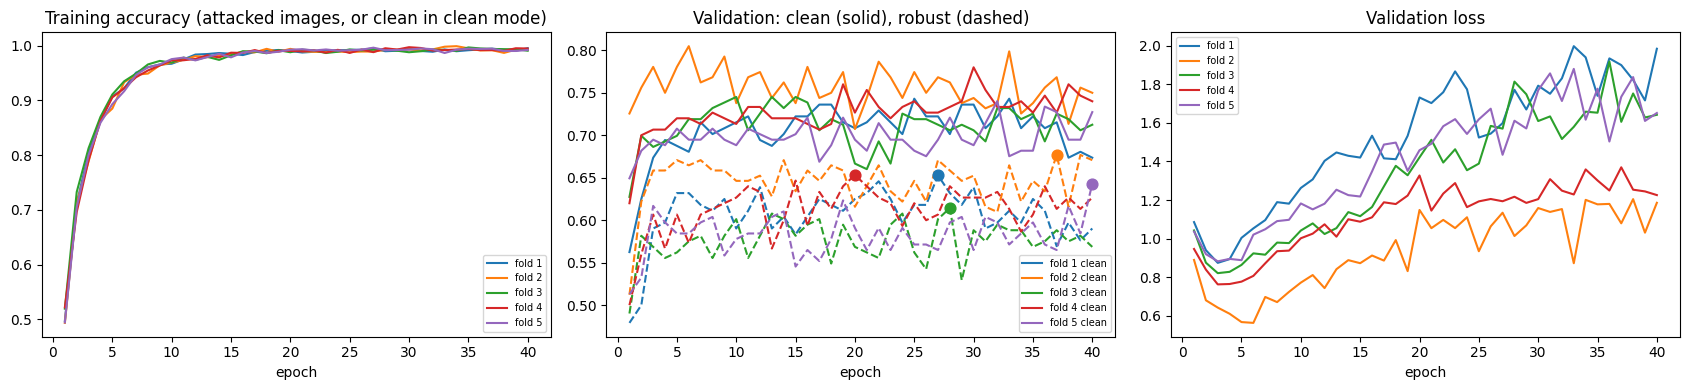

In [10]:
logs = {}
for k in FOLDS:
    with open(OUT / f"fold{k}.json") as f:
        logs[k] = json.load(f)
print("Best epoch per fold:", {k: logs[k]["best_epoch"] for k in FOLDS})

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for k in FOLDS:
    h = pd.DataFrame(logs[k]["hist"]); b = logs[k]["best_epoch"]
    line, = axes[0].plot(h.epoch, h.train_adv_acc, label=f"fold {k}"); c = line.get_color()
    axes[1].plot(h.epoch, h.val_acc, color=c, label=f"fold {k} clean")
    axes[1].plot(h.epoch, h.val_rob_acc, color=c, ls="--")
    axes[1].scatter(b, h.val_rob_acc[h.epoch == b], color=c, s=60, zorder=3)
    axes[2].plot(h.epoch, h.val_loss, color=c, label=f"fold {k}")
for ax, t in zip(axes, ["Training accuracy (attacked images, or clean in clean mode)", "Validation: clean (solid), robust (dashed)", "Validation loss"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 10. Results

Clean test accuracy and APGD-DLR robust accuracy, mean ± sample standard deviation over five folds, for the final and the best-validation weights. Compare with B0 in the plot that follows. The attack settings must be quoted with every number: untargeted L-infinity, APGD with the DLR loss, 20 steps, 1 restart, full precision, evaluation mode, raw pixel space.

In [11]:
def agg(which):
    rows = {}
    cl = [logs[k][which]["acc"] for k in FOLDS]
    rows["clean"] = (np.mean(cl), np.std(cl, ddof=1) if len(cl) > 1 else 0.0)
    for e in EVAL_EPS255:
        a = [logs[k][f"apgd_{which}"].get(str(e), {}).get("acc", np.nan) for k in FOLDS]
        rows[f"{e}/255"] = (np.nanmean(a), np.nanstd(a, ddof=1) if len(a) > 1 else 0.0)
    return rows

table = {}
for which, name in [("final", "E3 final"), ("bestval", "E3 best-val")]:
    table[name] = {k: f"{m:.2f} ± {s:.2f}" for k, (m, s) in agg(which).items()}
display(pd.DataFrame(table).T)

# Mpox recall and miss rate under attack
rows = []
for which in ("final", "bestval"):
    row = {"weights": which, "clean mpox recall": np.mean([logs[k][which]["mpox_sens"] for k in FOLDS])}
    for e in EVAL_EPS255:
        r = [logs[k][f"apgd_{which}"].get(str(e)) for k in FOLDS]
        if all(r):
            row[f"recall {e}/255"] = np.mean([v["mpox_recall"] for v in r])
            row[f"miss {e}/255"] = np.mean([v["mpox_miss"] for v in r])
    rows.append(row)
mp_table = pd.DataFrame(rows).set_index("weights")
display(mp_table.round(3))

pd.DataFrame(table).T.to_csv(OUT / f"{RUN_NAME}_accuracy_table.csv")
mp_table.to_csv(OUT / f"{RUN_NAME}_mpox_table.csv")

/tmp/ipykernel_23/1219192176.py:7: RuntimeWarning: Mean of empty slice
  rows[f"{e}/255"] = (np.nanmean(a), np.nanstd(a, ddof=1) if len(a) > 1 else 0.0)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


,clean,0.05/255,0.1/255,0.25/255,0.5/255,1.0/255,2.0/255
E3 final,75.26 ± 4.31,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan
E3 best-val,74.67 ± 6.16,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan,nan ± nan


,clean mpox recall
weights,
final,0.797
bestval,0.729


### Accuracy against epsilon, E3 versus B0

The B0 curves are typed in from the APGD-DLR evaluation of the baseline (see the settings cell). Add B2 here once its attack run is done.

/tmp/ipykernel_23/1085498611.py:7: RuntimeWarning: Mean of empty slice
  [np.nanmean([logs[k][f"apgd_{which}"].get(str(e), {}).get("acc", np.nan) for k in FOLDS]) for e in EVAL_EPS255]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


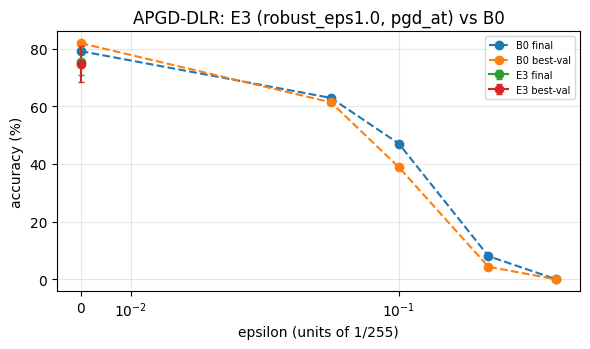

In [12]:
fig, ax = plt.subplots(figsize=(6, 3.6))
for name, ys in B0_ACC.items():
    ax.plot(B0_EPS, ys, marker="o", ls="--", label=name)
for which, name in [("final", "E3 final"), ("bestval", "E3 best-val")]:
    xs = [0] + EVAL_EPS255
    mean = [np.mean([logs[k][which]["acc"] for k in FOLDS])] + \
           [np.nanmean([logs[k][f"apgd_{which}"].get(str(e), {}).get("acc", np.nan) for k in FOLDS]) for e in EVAL_EPS255]
    std = [np.std([logs[k][which]["acc"] for k in FOLDS], ddof=1)] + \
          [np.nanstd([logs[k][f"apgd_{which}"].get(str(e), {}).get("acc", np.nan) for k in FOLDS], ddof=1) for e in EVAL_EPS255]
    ax.errorbar(xs, mean, yerr=std, marker="o", capsize=2, label=name)
ax.set_xscale("symlog", linthresh=0.05); ax.set_xlabel("epsilon (units of 1/255)"); ax.set_ylabel("accuracy (%)")
ax.set_title(f"APGD-DLR: E3 ({PRETRAIN}, {LOSS_MODE}) vs B0"); ax.grid(alpha=.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / f"{RUN_NAME}_acc_vs_eps.png", dpi=150); plt.show()

## 11. Confusion matrix on clean test images

Summed over the five folds for the final weights and row-normalised, as for B0 and B2. Check whether the mpox row and its confusion with chickenpox and cowpox changed after adversarial training.

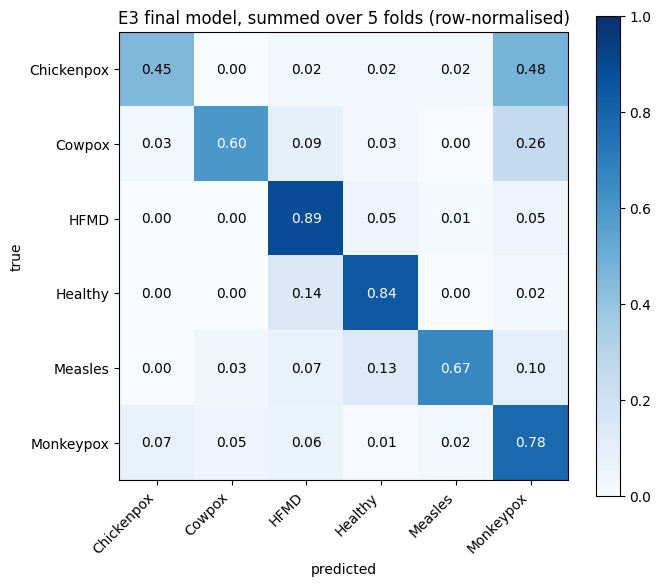

In [13]:
cm = sum(confusion_matrix(logs[k]["labels"], logs[k]["preds_final"], labels=range(NUM_CLASSES)) for k in FOLDS)
cm_norm = cm / cm.sum(1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASSES)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("E3 final model, summed over 5 folds (row-normalised)")
plt.colorbar(im); plt.tight_layout(); plt.show()

## Notes for the report

State: E3 fine-tunes a ResNet-50 (global average pooling head with 12,294 parameters, 23,520,326 in total) initialised from the setting in `PRETRAIN` (for the robust options, the L-infinity ResNet-50 checkpoint of Salman et al. trained at that budget), with `LOSS_MODE` as the training objective, training budget, attack steps, learning rates (1e-5 for the backbone, 1e-4 for the head), epochs and REPEAT from the settings cell. Attacks were built in eval mode in raw [0,1] pixel space with the ImageNet normalisation inside the model, the best-validation weights were chosen by robust validation accuracy at `VAL_EPS255`, and the final evaluation was APGD-DLR (20 steps, 1 restart, full precision) at the listed budgets.

How to read the outcome: compare with B0 and E1 at 0.25 and 0.5/255, where B0 reaches 8% and 0%, and watch clean accuracy and mpox recall. The three runs suggested in the introduction separate the effects: robust_eps1.0 + clean shows what the pretrained features give without any attack in training; robust_eps1.0 + pgd_at is the main result; standard + pgd_at shows how much the robust initialisation adds on top of adversarial training. Do not compare ResNet-50 and DenseNet121 numbers as a pure architecture effect, since the training recipes differ. As for E1, the evaluation attack here is the only number that counts, and a final check with more steps, restarts and a transfer attack is needed before claiming robustness.
